In [191]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/cjames36/patient-data-analytics/healthcare_patient_analytics_transformed.csv


# Importing

In [192]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

In [193]:
# THE DATA IN THIS DATASET IS SYNTHETIC AND DOES NOT REFLECT ACTUAL HEALTHCARE ANALYTICS 
df = pd.read_csv('/kaggle/input/datasets/cjames36/patient-data-analytics/healthcare_patient_analytics_transformed.csv')

# Gathering Data

In [194]:
df.head()

,patient_id,date_of_visit,age_group,gender,region,...,visit_type,length_of_stay_days,treatment_cost,recovery_score,readmission_risk
0,1,1/1/2022,31-45,Male,West,...,Emergency,5.8,59151,59,0.12
1,2,1/1/2022,60+,Female,West,...,Routine,5.1,30272,97,0.11
2,3,1/1/2022,46-60,Male,South,...,Routine,7.9,67498,60,0.19
3,4,1/1/2022,31-45,Female,North,...,Routine,5.0,29896,51,0.47
4,5,1/1/2022,18-30,Female,North,...,Routine,0.0,36208,60,0.40


In [195]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   patient_id           5000 non-null   int64  
 1   date_of_visit        5000 non-null   object 
 2   age_group            5000 non-null   object 
 3   gender               5000 non-null   object 
 4   region               5000 non-null   object 
 5   department           5000 non-null   object 
 6   treatment_type       5000 non-null   object 
 7   visit_type           5000 non-null   object 
 8   length_of_stay_days  5000 non-null   float64
 9   treatment_cost       5000 non-null   int64  
 10  recovery_score       5000 non-null   int64  
 11  readmission_risk     5000 non-null   float64
dtypes: float64(2), int64(3), object(7)
memory usage: 468.9+ KB


In [196]:
df.describe()

,patient_id,length_of_stay_days,treatment_cost,recovery_score,readmission_risk
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,2500.500000,4.059660,54915.471800,74.718800,0.280966
std,1443.520003,1.928847,19481.160487,11.870481,0.157178
min,1.000000,0.000000,746.000000,33.000000,0.010000
25%,1250.750000,2.700000,41244.750000,67.000000,0.160000
50%,2500.500000,4.000000,55123.500000,75.000000,0.260000
75%,3750.250000,5.400000,68012.000000,83.000000,0.380000
max,5000.000000,11.900000,119307.000000,100.000000,0.840000


# Data Exploration 

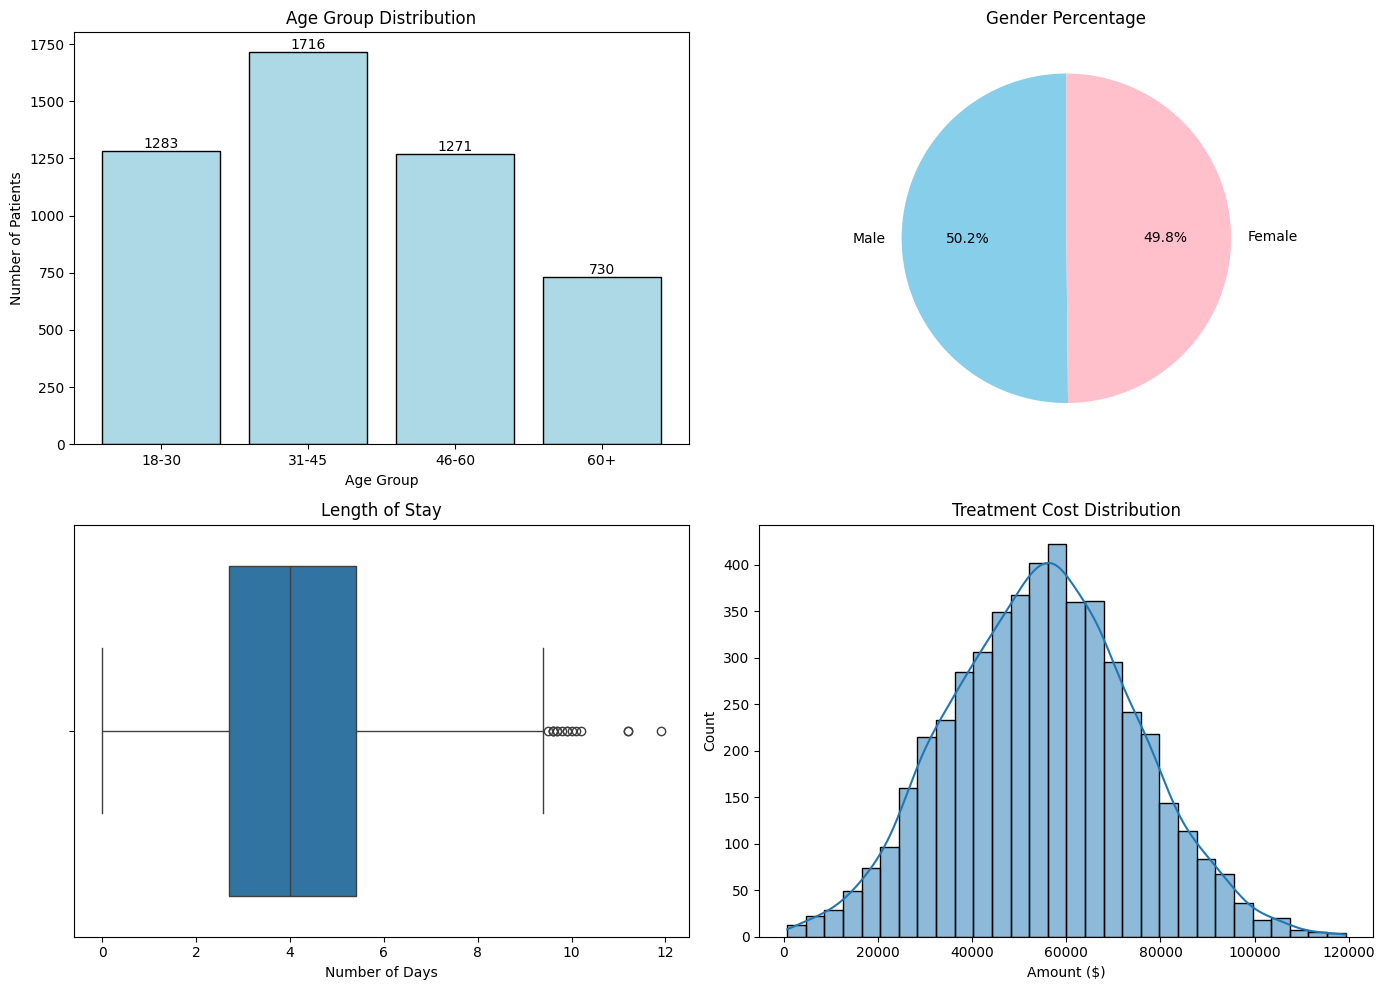

In [198]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

#Age Group Bar Chart
age_counts = df['age_group'].value_counts().sort_index()
bars = axes[0, 0].bar(age_counts.index, age_counts.values, color='lightblue', edgecolor='black')
axes[0, 0].set_title('Age Group Distribution')
axes[0, 0].set_xlabel('Age Group')
axes[0, 0].set_ylabel('Number of Patients')

# Data labels for Age Group 
for bar in bars:
    height = bar.get_height()
    if height > 0:
        axes[0, 0].annotate(f'{int(height)}',
                            (bar.get_x() + bar.get_width() / 2., height),
                            ha='center', va='bottom')

#Gender Distribution Pie Chart
gender_counts = df['gender'].value_counts()
axes[0, 1].pie(
    gender_counts, 
    labels=gender_counts.index, 
    autopct='%1.1f%%', 
    startangle=90,
    colors=['skyblue', 'pink'])
axes[0, 1].set_title('Gender Percentage')

# Length of Stay Boxplot
sns.boxplot(data=df, x='length_of_stay_days', ax=axes[1, 0])
axes[1, 0].set_title('Length of Stay')
axes[1, 0].set_xlabel('Number of Days')

#Treatment Cost Histogran 
sns.histplot(data=df, x='treatment_cost', bins=30, kde=True, ax=axes[1, 1])
axes[1, 1].set_title('Treatment Cost Distribution')
axes[1, 1].set_xlabel('Amount ($)')

plt.tight_layout()
plt.show()

- Age Group Chart: The 31–45 age bracket represents the largest patient cohort, followed by the 18–30, 46-60, and 60+ groups.

- Gender Chart: There are slightly more male patients than female patients.  

- Length of Stay Chart: Stays range from 0 to 12 days, with an overall average of 4 days. Most patients stay between 2.5 and 5.5 days, with several stretching out to 9–12 days.

- Treatment Cost Chart: Costs span from 746 to 119,307, averaging 54,915.47, with the majority ranging between 41,244.75 and 68,012.00 dollars.

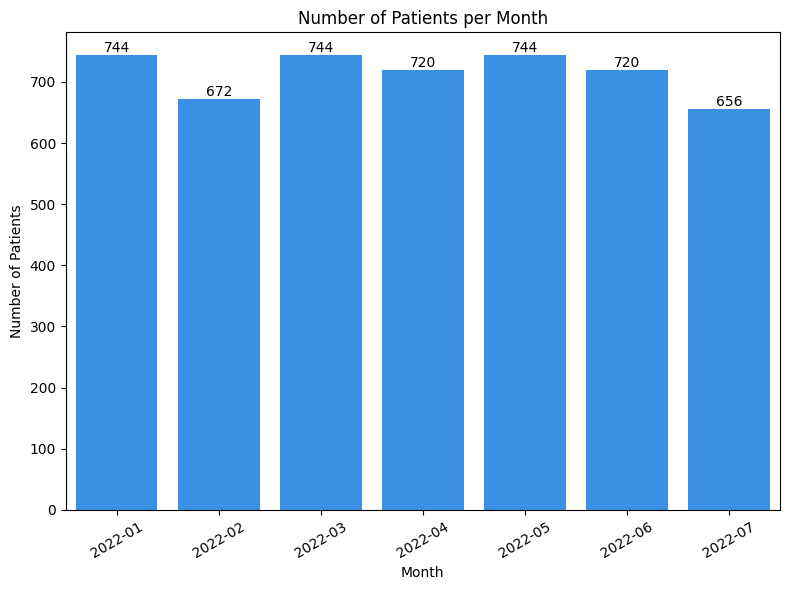

In [199]:
# Converting the date using Pandas
df['date_of_visit'] = pd.to_datetime(df['date_of_visit'])

# Extracting the 'Year-Month' and count patients per month
df['year_month'] = df['date_of_visit'].dt.to_period('M')
monthly_counts = df['year_month'].value_counts().sort_index()

# Visualizing number of patients per month
plt.figure(figsize=(8,6))
ax = sns.barplot(x=monthly_counts.index.astype(str), y=monthly_counts.values, color='dodgerblue')

plt.title('Number of Patients per Month')
plt.xlabel('Month')
plt.ylabel('Number of Patients')

# Data labels
for container in ax.containers:
    ax.bar_label(container)

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

January, March, and May saw the highest patient count with 744 each. April and June had a count of 720 patients each. February experienced the second-lowest count at 672 patients, while July had the lowest count at 656 patients.

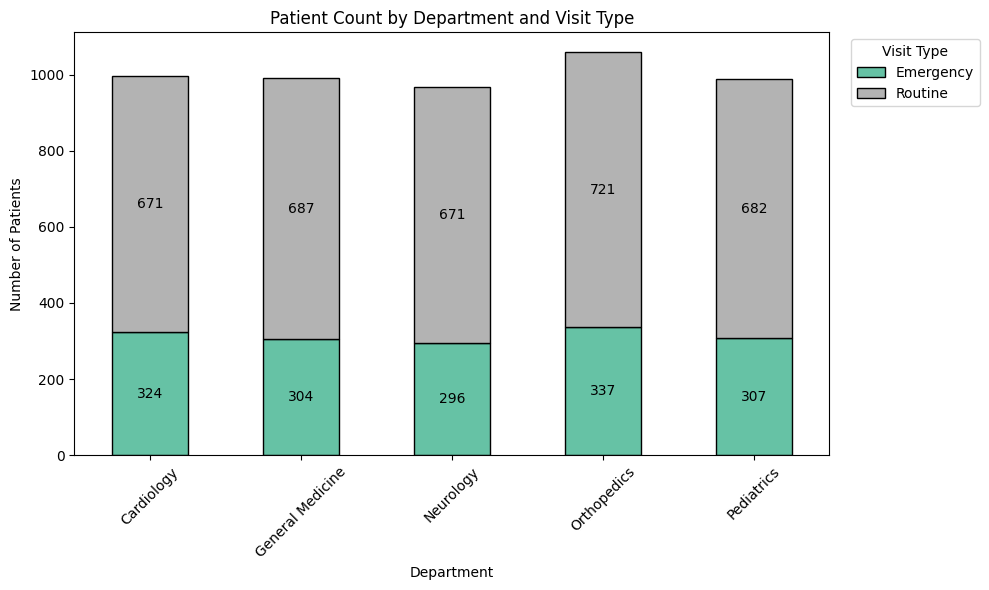

In [200]:
# Making a crosstab since both are categorical 
dep_visit = pd.crosstab(df['department'], df['visit_type'])

# Creating a Stacked Bar Chart to visualize the data
ax = dep_visit.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='Set2', edgecolor='black')

plt.title('Patient Count by Department and Visit Type')
plt.xlabel('Department')
plt.ylabel('Number of Patients')
plt.xticks(rotation=45)
plt.legend(title='Visit Type', bbox_to_anchor=(1.02, 1), loc='upper left')

for container in ax.containers:
    ax.bar_label(container, label_type='center', color='black')

plt.tight_layout()
plt.show()

- The Orthopedic department had the highest volume, leading with 721 routine visits and 337 emergency admissions.

- The Cardiology and Neurology department shared identical numbers of routine patients, but differed in emergency admissions, with Cardiology having 324 emergencies compared to Neurology's 296.

- The General Medicine and Pediatrics department closely matched across both routine and emergency care categories.

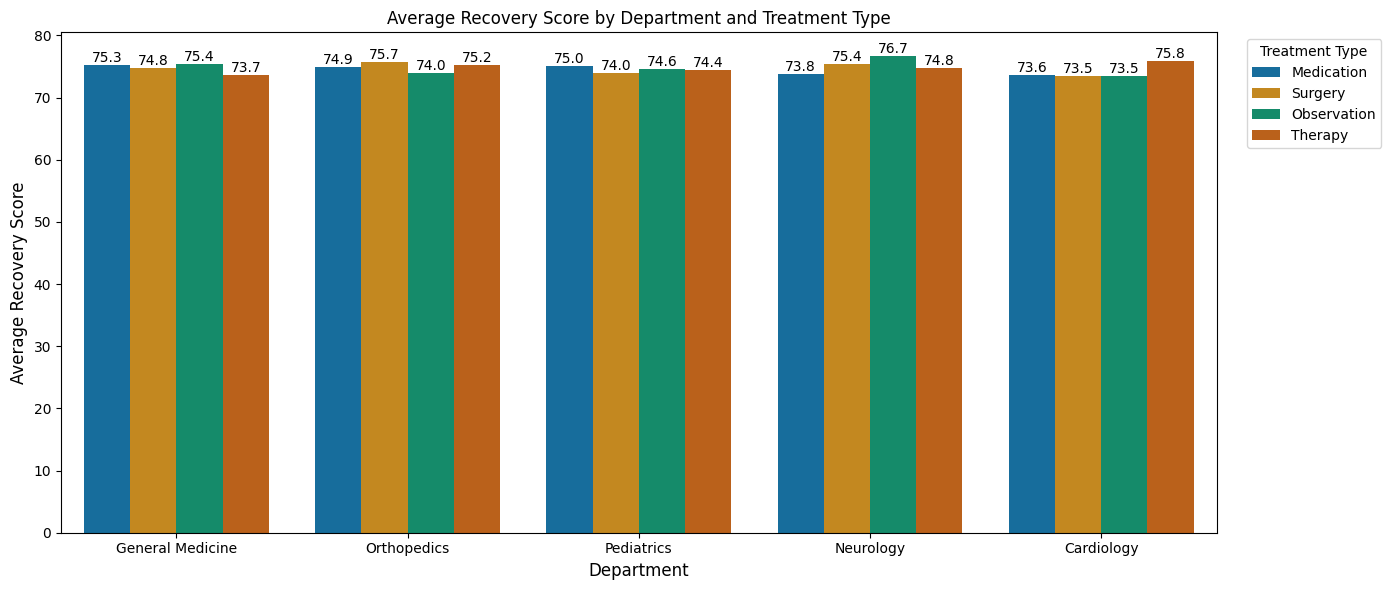

In [201]:
plt.figure(figsize=(14, 6))

# Creating a Grouped Bar Chart
ax = sns.barplot(data=df,x='department',y='recovery_score',hue='treatment_type',palette='colorblind',errorbar=None)

# Data labels
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f')

plt.title('Average Recovery Score by Department and Treatment Type')
plt.xlabel('Department',fontsize=12)
plt.ylabel('Average Recovery Score',fontsize=12)

# Legend
plt.legend(title='Treatment Type', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

- The General Medicine department showed nearly identical recovery scores across medication and observation treatments.

- The Orthopedics department achieved the highest recovery scores through surgery, followed closely by therapy.

- The Pediatrics department recorded the best recovery outcomes utilizing medication.

- The Neurology department achieved high recovery scores through observation.

- The Cardiology department had the highest recovery performance using therapy

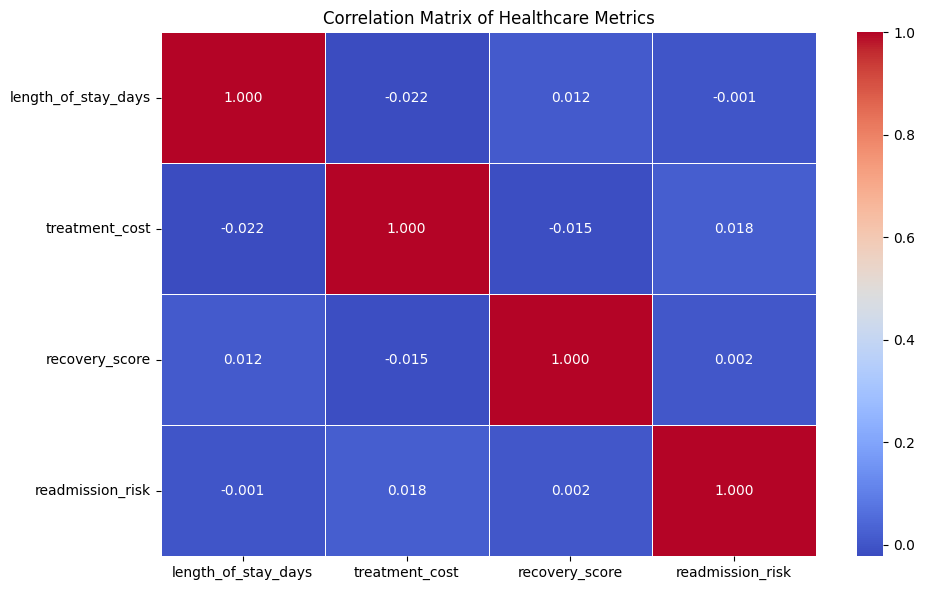

In [202]:
# Grouping numerical columns
numeric_cols = ['length_of_stay_days', 'treatment_cost', 'recovery_score', 'readmission_risk']
corr_matrix = df[numeric_cols].corr()

# Creating a Heatmap
plt.figure(figsize=(10,6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm',fmt='.3f',linewidths=0.5)

plt.title('Correlation Matrix of Healthcare Metrics')
plt.tight_layout()
plt.show()

- The correlation analysis indicates no significant linear relationship among length of stay, treatment cost, recovery score, and readmission risk, suggesting that treatment costs and lengths of stay do not strictly dictate recovery scores or readmission likelihoods.